# Experiment 1: efficiency as sample size increases

The correctly specified DGP is $x=u+as+v$ and $y=\beta x+u+\epsilon$. We use $a\in\{1,2,3\}$, $n\in\{200,400,\ldots,2000\}$, $\beta=1$, and 1,000 Monte Carlo replications per design point. The main figure places the MSE curves for $a=1,2,3$ in one horizontal row. WLS is excluded.

All methods estimate the IV and SV projections from each sample. IV-only, SV-only, and combined efficient GMM each estimate a two-step weight from their own projected first-order scores in Remark 7 and Appendix D. Because the single-channel scalar systems are exactly identified, their second-step weights do not change their point estimates.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / "results" / "efficiency" / "efficiency_replications.csv").exists():
    root = root / "unification-control-modelling"
result_dir = root / "results" / "efficiency"
raw = pd.read_csv(result_dir / "efficiency_replications.csv")
summary = pd.read_csv(result_dir / "efficiency_summary.csv")
assert len(raw) == 600_000 and len(summary) == 600
assert set(summary["replications"]) == {1000}
methods = ["iv", "sv", "equal", "feasible_efficient"]
labels = {"iv": "IV only", "sv": "SV only", "equal": "Equal GMM", "feasible_efficient": "Efficient GMM"}
colors = {"iv": "#4477AA", "sv": "#EE6677", "equal": "#228833", "feasible_efficient": "#332288"}
markers = {"iv": "o", "sv": "s", "equal": "^", "feasible_efficient": "D"}
a_values = [1.0, 2.0, 3.0]
n_values = list(range(200, 2001, 200))
a_names = ["1", "2", "3"]


## Main figure: MSE by sample size

Each panel reports Monte Carlo MSE for one value of $a$. The dashed black curve is the population efficient asymptotic variance divided by $n$. This layout shows how the relative MSE ranking changes from the SV-dominant design at $a=1$, through the balanced design at $a=2$, to the IV-dominant design at $a=3$.


In [2]:
est = raw[raw["scenario"] == "estimation"].copy()
est["error"] = est["beta_hat"] - est["beta"]
est["squared_error"] = est["error"] ** 2
metrics = est.groupby(["a", "n", "method"], as_index=False).agg(
    replications=("error", "size"),
    bias=("error", "mean"),
    mse=("squared_error", "mean"),
)
metrics["bias_squared"] = metrics["bias"] ** 2
metrics["variance"] = metrics["mse"] - metrics["bias_squared"]
assert np.allclose(metrics["mse"], metrics["bias_squared"] + metrics["variance"])
metrics.to_csv(result_dir / "efficiency_decomposition.csv", index=False)
metrics.head()


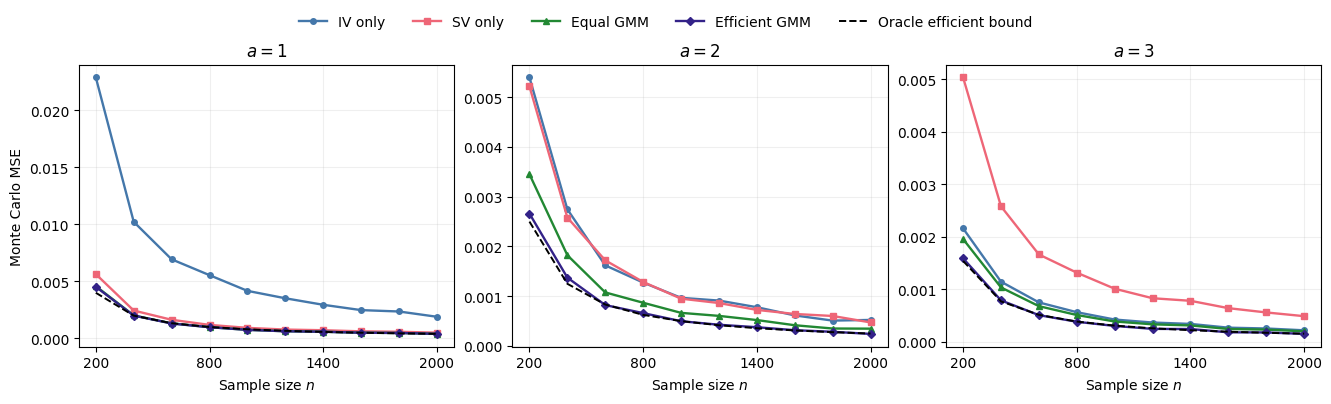

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.6), sharex=True, constrained_layout=True)
for ax, a, a_name in zip(axes, a_values, a_names):
    data = metrics[np.isclose(metrics["a"], a)]
    for method in methods:
        part = data[data["method"] == method].sort_values("n")
        ax.plot(part["n"], part["mse"], marker=markers[method], markersize=4,
                color=colors[method], linewidth=1.7, label=labels[method])
    ax.plot(n_values, 4 / ((a**2 + 4) * np.array(n_values)),
            color="black", linestyle="--", linewidth=1.4,
            label="Oracle efficient bound")
    ax.set_title(rf"$a={a_name}$")
    ax.set_xlabel("Sample size $n$")
    ax.set_xticks([200, 800, 1400, 2000])
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Monte Carlo MSE")
handles, legend_labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", bbox_to_anchor=(0.5, 1.10),
           ncol=5, frameon=False)
fig.savefig(result_dir / "efficiency_mse.pdf", bbox_inches="tight")
fig.savefig(result_dir / "efficiency_mse.png", dpi=300, bbox_inches="tight")
plt.show()


## Compact summaries for each value of $a$

The table compares feasible efficient GMM with whichever single-channel method has the smaller MSE at that same $(a,n)$. The “MSE gain” is relative to that best single channel. Squared bias, variance, and MSE are reported separately so the source of the gain is visible. Full results for every method and $n$ are saved in `results/efficiency/efficiency_decomposition.csv`.


In [4]:
story_rows = []
for a, a_name in zip(a_values, a_names):
    for n in n_values:
        part = metrics[np.isclose(metrics["a"], a) & (metrics["n"] == n)].set_index("method")
        best_single = min(["iv", "sv"], key=lambda method: part.loc[method, "mse"])
        efficient = part.loc["feasible_efficient"]
        story_rows.append({
            "a": a, "n": n, "best_single": labels[best_single],
            "best_single_mse": part.loc[best_single, "mse"],
            "efficient_bias": efficient["bias"],
            "efficient_bias_squared": efficient["bias_squared"],
            "efficient_variance": efficient["variance"],
            "efficient_mse": efficient["mse"],
            "mse_gain": 1 - efficient["mse"] / part.loc[best_single, "mse"],
        })
story = pd.DataFrame(story_rows)
story.to_csv(result_dir / "efficiency_story_summary.csv", index=False)
for a, a_name in zip(a_values, a_names):
    print(f"a = {a_name}")
    part = story[np.isclose(story["a"], a)].drop(columns="a").set_index("n")
    display(part.style.format({
        "best_single_mse": "{:.5f}", "efficient_bias": "{:+.5f}",
        "efficient_bias_squared": "{:.6f}", "efficient_variance": "{:.5f}",
        "efficient_mse": "{:.5f}", "mse_gain": "{:.1%}",
    }))


a = 1
a = 2
a = 3


## Main-paper summary table

At the representative sample size $n=1000$, the table puts empirical $n\times\mathrm{MSE}$ next to the oracle efficient asymptotic variance. The bound is a benchmark for efficient GMM, not the theoretical variance of equal-weight GMM. For equal weighting, the correct asymptotic variance is $(a^6/4+1)/(a^4/4+1)^2$, equal to 0.80, 0.68, and 0.41 for $a=1,2,3$. The gain column compares efficient GMM with the lower-MSE single channel.


In [5]:
main_rows = []
for a, a_name in zip(a_values, a_names):
    part = metrics[np.isclose(metrics["a"], a) & (metrics["n"] == 1000)].set_index("method")
    best_single = min(part.loc["iv", "mse"], part.loc["sv", "mse"])
    main_rows.append({
        "a": a_name,
        "iv_scaled_mse": 1000 * part.loc["iv", "mse"],
        "sv_scaled_mse": 1000 * part.loc["sv", "mse"],
        "equal_scaled_mse": 1000 * part.loc["equal", "mse"],
        "efficient_scaled_mse": 1000 * part.loc["feasible_efficient", "mse"],
        "oracle_efficient_bound": 4 / (a**2 + 4),
        "mse_gain_vs_best_single": 1 - part.loc["feasible_efficient", "mse"] / best_single,
    })
main_table = pd.DataFrame(main_rows).set_index("a")
main_table.to_csv(result_dir / "efficiency_main_table.csv")
display(main_table.style.format({
    "iv_scaled_mse": "{:.3f}", "sv_scaled_mse": "{:.3f}",
    "equal_scaled_mse": "{:.3f}", "efficient_scaled_mse": "{:.3f}",
    "oracle_efficient_bound": "{:.3f}", "mse_gain_vs_best_single": "{:.1%}",
}))


## Inference summaries

Type I error, local power, and coverage are retained in the CSV summaries but are not plotted in this notebook figure.


In [6]:
inference = raw[raw["scenario"].isin(["size", "power_1", "power_2"])].groupby(
    ["scenario", "a", "n", "method"], as_index=False
).agg(
    replications=("reject_h0_beta_0", "size"),
    rejection_rate=("reject_h0_beta_0", "mean"),
    coverage=("covered", "mean"),
)
inference.to_csv(result_dir / "efficiency_inference_summary.csv", index=False)


The compact table below pairs Type I error and local power for efficient GMM with the best single channel from the MSE comparison. The full inference CSV also contains the $\beta=1/\sqrt n$ power scenario and all methods.


In [7]:
infer_rows = []
for _, item in story.iterrows():
    a, n = item["a"], item["n"]
    best_method = "iv" if item["best_single"] == "IV only" else "sv"
    part = inference[np.isclose(inference["a"], a) & (inference["n"] == n)]
    rates = part.pivot(index="method", columns="scenario", values="rejection_rate")
    infer_rows.append({
        "a": a, "n": n,
        "efficient_type_i": rates.loc["feasible_efficient", "size"],
        "efficient_power_1": rates.loc["feasible_efficient", "power_1"],
        "efficient_power_2": rates.loc["feasible_efficient", "power_2"],
        "best_single": item["best_single"],
        "best_single_power_2": rates.loc[best_method, "power_2"],
    })
infer_table = pd.DataFrame(infer_rows)
infer_table.to_csv(result_dir / "efficiency_inference_story_summary.csv", index=False)
for a, a_name in zip(a_values, a_names):
    print(f"a = {a_name}")
    display(infer_table[np.isclose(infer_table["a"], a)].drop(columns="a").set_index("n").style.format({
        "efficient_type_i": "{:.3f}", "efficient_power_1": "{:.3f}",
        "efficient_power_2": "{:.3f}", "best_single_power_2": "{:.3f}",
    }))


a = 1
a = 2
a = 3


## Main points for the paper

- **$a=1$ (SV is stronger):** IV-only has the highest MSE. Efficient GMM improves on SV-only across the sample-size grid.
- **$a=2$ (balanced):** IV and SV have equal asymptotic variances; efficient GMM combines their complementary information.
- **$a=3$ (IV is stronger):** IV-only becomes more precise than SV-only, while efficient GMM can still gain from combining both channels.

In all three regimes, bias is small relative to the standard deviation and the MSE pattern is driven mainly by variance. The theoretical curve is an asymptotic population benchmark, so finite-sample points need not lie on it. These conclusions apply to sample-estimated projections under correct specification.

The single paper figure is saved as `efficiency_mse.pdf` and `efficiency_mse.png` in `results/efficiency/`. The CSV summaries retain the full bias, variance, MSE, Type I error, local-power, and coverage results.

**Theory note.** Under the sample-projection estimator in (3.3), the SV first-order score in (3.5) is $v\epsilon$ for this DGP. Hence $V_{\mathrm{SV}}=1$ and the efficient combined benchmark is $4/(a^2+4)$; the equal-information case is $a=2$.
